# Regression

##### Linear regression: Linear Regression is a statistical method used to model the relationship between a dependent variable and one or more independent variables by fitting a straight line (called the regression line) to the data.

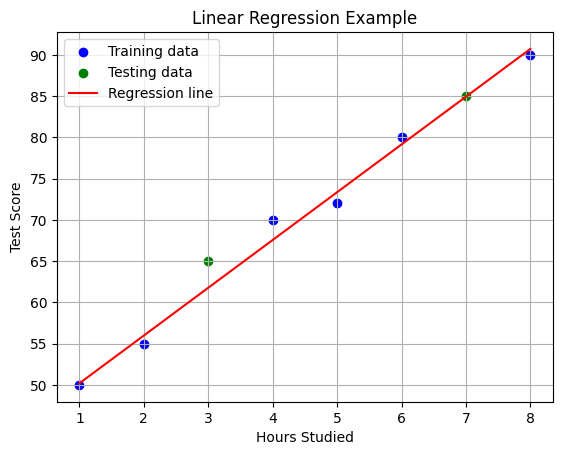

In [2]:
#example 
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# Sample data: X = hours studied, y = test scores
X = np.array([[1], [2], [3], [4], [5], [6], [7], [8]])
y = np.array([50, 55, 65, 70, 72, 80, 85, 90])

# Split into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# Create and train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict on test data
y_pred = model.predict(X_test)

# Plotting the results
plt.scatter(X_train, y_train, color='blue', label='Training data')
plt.scatter(X_test, y_test, color='green', label='Testing data')
plt.plot(X, model.predict(X), color='red', label='Regression line')
plt.xlabel('Hours Studied')
plt.ylabel('Test Score')
plt.title('Linear Regression Example')
plt.legend()
plt.grid(True)
plt.show()

##### Logistic Regression: Logistic Regression is a classification algorithm used to predict the probability of a binary outcome (e.g., yes/no, 0/1, true/false).
###### It models the relationship between input features and the probability of a particular class using a sigmoid function, which outputs values between 0 and 1.

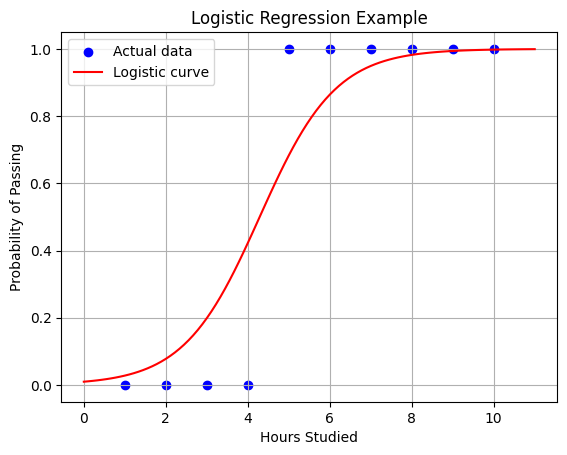

In [3]:
#example
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# Sample data: X = hours studied, y = 0 (fail) or 1 (pass)
X = np.array([[1], [2], [3], [4], [5], [6], [7], [8], [9], [10]])
y = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1, 1])  # 0 = Fail, 1 = Pass

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

# Train logistic regression model
model = LogisticRegression()
model.fit(X_train, y_train)

# Predict probabilities for visualization
X_range = np.linspace(0, 11, 100).reshape(-1, 1)
y_prob = model.predict_proba(X_range)[:, 1]

# Plot
plt.scatter(X, y, color='blue', label='Actual data')
plt.plot(X_range, y_prob, color='red', label='Logistic curve')
plt.xlabel('Hours Studied')
plt.ylabel('Probability of Passing')
plt.title('Logistic Regression Example')
plt.legend()
plt.grid(True)
plt.show()

###### Lasso Regression (Least Absolute Shrinkage and Selection Operator) is a linear regression technique that uses L1 regularization to penalize the absolute size of the regression coefficients.
###### It is used to:
###### 1) Prevent overfitting
###### 2) Perform feature selection (by shrinking some coefficients to exactly zero)

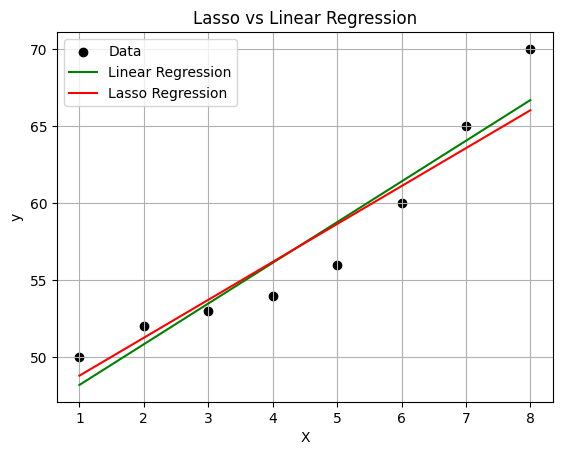

In [4]:
# example 
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.model_selection import train_test_split

# Sample data
X = np.array([[1], [2], [3], [4], [5], [6], [7], [8]])
y = np.array([50, 52, 53, 54, 56, 60, 65, 70])

# Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# Fit Lasso regression
lasso_model = Lasso(alpha=1.0)
lasso_model.fit(X_train, y_train)

# Fit regular linear regression for comparison
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Predict over full range for visualization
X_range = np.linspace(1, 8, 100).reshape(-1, 1)
y_lasso = lasso_model.predict(X_range)
y_linear = linear_model.predict(X_range)

# Plot
plt.scatter(X, y, color='black', label='Data')
plt.plot(X_range, y_linear, color='green', label='Linear Regression')
plt.plot(X_range, y_lasso, color='red', label='Lasso Regression')
plt.xlabel('X')
plt.ylabel('y')
plt.title('Lasso vs Linear Regression')
plt.legend()
plt.grid(True)
plt.show()

##### Multiple Linear Regression:  Uses two or more independent variables to predict a dependent variable.


In [5]:
# example
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt

# Sample data: [hours studied, hours slept] => test score
X = np.array([[1, 6], [2, 5], [3, 5], [4, 4], [5, 4], [6, 3], [7, 3], [8, 2]])
y = np.array([55, 58, 60, 62, 68, 70, 75, 78])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

model = LinearRegression()
model.fit(X_train, y_train)

print("Predicted score for 5 hrs study, 4 hrs sleep:", model.predict([[5, 4]])[0])

Predicted score for 5 hrs study, 4 hrs sleep: 68.21428571428572


##### polynomial regression:  Extends linear regression by considering polynomial (e.g. squared, cubic) features of the input.

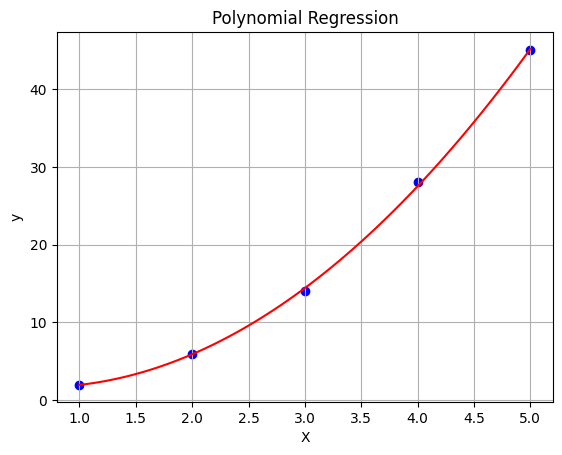

In [6]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

X = np.array([[1], [2], [3], [4], [5]])
y = np.array([2, 6, 14, 28, 45])  # Clearly non-linear

poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)

model = LinearRegression()
model.fit(X_poly, y)

X_range = np.linspace(1, 5, 100).reshape(-1, 1)
y_pred = model.predict(poly.transform(X_range))

plt.scatter(X, y, color='blue')
plt.plot(X_range, y_pred, color='red')
plt.title('Polynomial Regression')
plt.xlabel('X')
plt.ylabel('y')
plt.grid(True)
plt.show()

##### Ridge Regression:  Linear regression with L2 regularization (shrinks coefficients but does not set to zero).

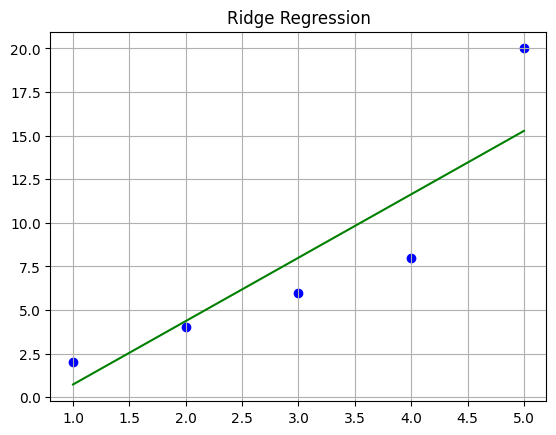

In [7]:
from sklearn.linear_model import Ridge

X = np.array([[1], [2], [3], [4], [5]])
y = np.array([2, 4, 6, 8, 20])  # Last point is an outlier

model = Ridge(alpha=1.0)
model.fit(X, y)

X_range = np.linspace(1, 5, 100).reshape(-1, 1)
y_pred = model.predict(X_range)

plt.scatter(X, y, color='blue')
plt.plot(X_range, y_pred, color='green')
plt.title('Ridge Regression')
plt.grid(True)
plt.show()

##### ElasticNet Regression: Combines L1 and L2 regularization (Lasso + Ridge). Helps with both overfitting and feature selection.

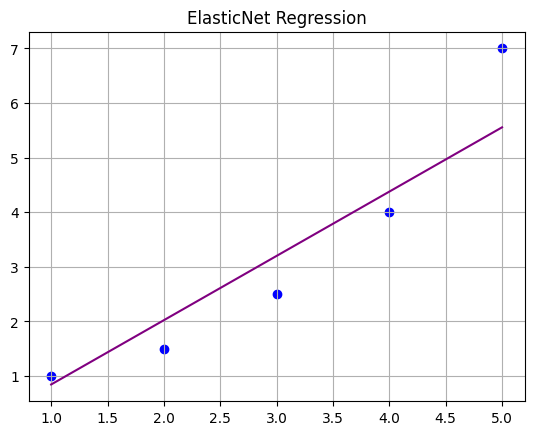

In [8]:
from sklearn.linear_model import ElasticNet

X = np.array([[1], [2], [3], [4], [5]])
y = np.array([1, 1.5, 2.5, 4, 7])  # Some non-linearity

model = ElasticNet(alpha=0.5, l1_ratio=0.5)
model.fit(X, y)

X_range = np.linspace(1, 5, 100).reshape(-1, 1)
y_pred = model.predict(X_range)

plt.scatter(X, y, color='blue')
plt.plot(X_range, y_pred, color='purple')
plt.title('ElasticNet Regression')
plt.grid(True)
plt.show()

##### Non-Linear Regression: Directly models non-linear relationships (often by fitting a non-linear function like exponential, logistic, etc.).

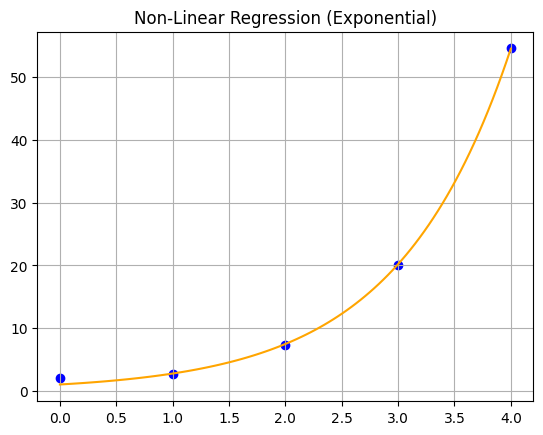

In [9]:
from scipy.optimize import curve_fit

# Example: y = a * exp(b*x)
def model_func(x, a, b):
    return a * np.exp(b * x)

X = np.array([0, 1, 2, 3, 4])
y = np.array([2.0, 2.7, 7.4, 20.1, 54.6])

params, _ = curve_fit(model_func, X, y)
a, b = params

X_range = np.linspace(0, 4, 100)
y_pred = model_func(X_range, a, b)

plt.scatter(X, y, color='blue')
plt.plot(X_range, y_pred, color='orange')
plt.title('Non-Linear Regression (Exponential)')
plt.grid(True)
plt.show()